# Make plots to compare massane field data to HLS satellite data

# libraries

In [1]:
import os
import sys

from matplotlib import colors

os.environ["PROJ_LIB"] = "/home/abernard/miniconda3/envs/phenosensing/share/proj"
os.environ["PROJ_DATA"] = "/home/abernard/miniconda3/envs/phenosensing/share/proj"
os.environ["GDAL_DATA"] = "/home/abernard/miniconda3/envs/phenosensing/share/gdal"


import geopandas as gpd
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import rioxarray as rio
import pandas as pd
import phenosensing
from rasterio.enums import Resampling

from pyproj import CRS

print(CRS.from_epsg(2154))

EPSG:2154


# other stuff

In [2]:
gdf = gpd.read_file("../data/RNN_limite_poly_l93.shp")

gdf = gdf.set_crs("EPSG:2154")

gdf = gdf.to_crs("EPSG:4326")


gdf2 = gpd.read_file("../data/limite_RI_wgs84.shp")
gdf2 = gdf2.set_crs("EPSG:4326")

/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received an unexpected geometry.  Either a polygon with interior rings, or a polygon with less than 4 points, or a non-Polygon geometry.  Return arguments as a collection.
  return ogr_read(
/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/pyogrio/raw.py:200: RuntimeWarning: Geometry of polygon of fid 0 cannot be translated to Simple Geometry. All polygons will be contained in a multipolygon.
  return ogr_read(


# HLS data

In [3]:
#### NET CDF ######

# HLS sentinel
ds_part1 = xr.open_dataset("../data/HLS_IMG/HLSS30.020_30m_2016.nc", decode_coords="all")
ds_part2 = xr.open_dataset("../data/HLS_IMG/HLSS30.020_30m_2017_2021.nc", decode_coords="all")
ds_part3 = xr.open_dataset("../data/HLS_IMG/HLSS30.020_30m_2022_2026.nc", decode_coords="all")

ds_s = xr.concat([ds_part1, ds_part2, ds_part3], dim="time")


# HLS landsat
ds_part1 = xr.open_dataset("../data/HLS_IMG/HLSL30.020_30m_2016.nc", decode_coords="all")
ds_part2 = xr.open_dataset("../data/HLS_IMG/HLSL30.020_30m_2017_2021.nc", decode_coords="all")
ds_part3 = xr.open_dataset("../data/HLS_IMG/HLSL30.020_30m_2022_2026.nc",decode_coords="all")

ds_l = xr.concat([ds_part1, ds_part2, ds_part3], dim="time", join="override")

ds_s2 = ds_s.rename({"B8A": "NIR"})
ds_l2 = ds_l.rename({"B05": "NIR"})

ds_s2 = ds_s2.assign_coords(sensor=("time", ["S30"] * ds_s2.sizes["time"]))
ds_l2 = ds_l2.assign_coords(sensor=("time", ["L30"] * ds_l2.sizes["time"]))

ds = xr.concat([ds_s2, ds_l2], dim="time", join="override").sortby("time")


# Dates où il y a plusieurs images
dates = pd.Index(ds.time.values)
dates_dupliquees = pd.unique(dates[dates.duplicated()])

# Masque des images à conserver
a_garder = ~(
    ds.time.isin(dates_dupliquees) &   # date dupliquée
    (ds.sensor == "L30")               # provenant de Landsat
)

ds = ds.sel(time=a_garder)

In [4]:
## compute the NDVI
red = ds["B04"]
nir = ds["NIR"]

ndvi = (nir - red) / (nir + red)
ds["NDVI"] = ndvi
ds["NDVI"].attrs = {
    "long_name": "Normalized Difference Vegetation Index"
}

In [5]:
fmask = ds["Fmask"].astype("uint8")
fmask = fmask.rio.write_crs("EPSG:4326")


# Décodage des bits Fmask
cloud = ((fmask >> 1) & 1) == 1
adjacent = ((fmask >> 2) & 1) == 1
shadow = ((fmask >> 3) & 1) == 1
snow = ((fmask >> 4) & 1) == 1


# Pixels conservés
good = (
    (~cloud)
    &
    (~adjacent)
    &
    (~shadow)
    &
    (~snow)
)

ds_clean = ds.where(good)

/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/xarray/core/duck_array_ops.py:268: RuntimeWarning: invalid value encountered in cast
  return data.astype(dtype, **kwargs)


In [6]:
# RN

clipped_ndvi = ds_clean["NDVI"].rio.clip(
    gdf.geometry,
    gdf.crs,
    drop=True
)


clipped_good = good.rio.clip(
    gdf.geometry,
    gdf.crs,
    drop=True
)

In [7]:
dates_valides = []
moyennes_ndvi = []
median_ndvi = []
ratios_good = []


for t in range(clipped_ndvi.sizes["time"]):

    ndvi_t = clipped_ndvi.isel(time=t)

    good_t = clipped_good.isel(time=t)


    # proportion de pixels valides
    ratio_good = good_t.mean().item()


    # garder seulement si >90% de pixels propres
    if ratio_good > 0.90:

        mean_ndvi = ndvi_t.where(good_t).mean().item()

        med_ndvi = ndvi_t.where(good_t).median().item()


        dates_valides.append(
            pd.to_datetime(str(ndvi_t.time.values))
        )

        moyennes_ndvi.append(mean_ndvi)
        median_ndvi.append(med_ndvi)

        ratios_good.append(ratio_good)

In [8]:
df = pd.DataFrame({
    "date": dates_valides,
    "mean_ndvi": moyennes_ndvi,
    "median_ndvi": median_ndvi,
    "ratio_good": ratios_good
})


df = df.sort_values("date")

df_clean = df[(df["mean_ndvi"] > 0.5) & (df["mean_ndvi"] < 0.9)]

In [9]:
import cftime

dates_valides_cftime = [  # nouveau xarr avec seulement les dates où -20% de pixels invalides
    cftime.DatetimeJulian(
        d.year,
        d.month,
        d.day
    )
    for d in dates_valides
]

ds_final = ds.sel(time=dates_valides_cftime)

In [10]:
ds_final["NDVI"] = ds_final["NDVI"].where(
    np.isfinite(ds_final["NDVI"]) &
    (ds_final["NDVI"] >= -1) &
    (ds_final["NDVI"] <= 1)
)

# deluzet maps

In [11]:
# Charger la carte
massane1 = rio.open_rasterio(
    "../data/Cartes_Deluzet/5class_maps/Massane1_RF.tif",
    masked=True
)

massane2 = rio.open_rasterio(
    "../data/Cartes_Deluzet/5class_maps/Massane2_RF.tif",
    masked=True
)

# reproj en wgs84
massane1_wgs84 = massane1.rio.reproject("EPSG:4326")
massane2_wgs84 = massane2.rio.reproject("EPSG:4326")

In [12]:
# grille cible :
template = ds_final["NDVI"].isel(time=0, drop=True)

template = template.rio.set_spatial_dims(
    x_dim="xdim",
    y_dim="ydim"
)

template = template.rio.write_crs("EPSG:4326")

In [13]:
# merger les deux massage de deluzet
from rioxarray.merge import merge_arrays

massane_wgs84 = merge_arrays([massane1_wgs84, massane2_wgs84])

In [14]:
veg = xr.where(
    massane_wgs84.notnull(),
    (massane_wgs84 != 0).astype("float32"),
    np.nan
)

print("Valeurs du masque :", np.unique(veg.values))

hetre = xr.where(
    massane_wgs84.notnull(),
    (massane_wgs84 == 2).astype("float32"),
    np.nan
)

print("Valeurs du masque :", np.unique(hetre.values))

Valeurs du masque : [ 0.  1. nan]
Valeurs du masque : [ 0.  1. nan]


In [15]:
# verifier les proportions avant le resampling

total = veg.size
total_hetre = hetre.size

n_veg = np.sum(veg.values == 1)
n_noveg = np.sum(veg.values == 0)
n_nodata = np.sum(np.isnan(veg.values))
n_hetre = np.sum(hetre.values == 1)
n_nohetre = np.sum(hetre.values == 0)

print()
print("Haute résolution :")
print(f"Végétation     : {100*n_veg/total:.2f} %")
print(f"Non-végétation : {100*n_noveg/total:.2f} %")
print(f"NoData         : {100*n_nodata/total:.2f} %")

print(f"Hetre          : {100*n_hetre/total_hetre:.2f} %")
print(f"No Hetre       : {100*n_nohetre/total_hetre:.2f} %")


Haute résolution :
Végétation     : 21.54 %
Non-végétation : 37.66 %
NoData         : 40.80 %
Hetre          : 13.37 %
No Hetre       : 45.83 %


In [16]:
veg_fraction = veg.rio.reproject_match(
    template,
    resampling=Resampling.average
)

veg_fraction = veg_fraction.squeeze()


hetre_fraction = hetre.rio.reproject_match(
    template,
    resampling=Resampling.average
)

hetre_fraction = hetre_fraction.squeeze()


veg_mask = veg_fraction.where(
    veg_fraction > 0.60
)

hetre_mask = hetre_fraction.where(
    hetre_fraction > 0.6
)

In [17]:
# rename les dimensions (très important pour la suite)
veg_mask = veg_mask.rename({
    "y": "ydim",
    "x": "xdim"
})

hetre_mask = hetre_mask.rename({
    "y": "ydim",
    "x": "xdim"
})

# phenos toutes les années

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr

years = [2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]

results = {}

for year in years:

    print(f"\n{'='*50}")
    print(f"ANNÉE {year}")
    print(f"{'='*50}")

    # --------------------------------------------------------
    # Sélection de l'année
    # --------------------------------------------------------

    HLS_year = ds_final.sel(
        time=ds_final.time.dt.year == year
    )

    # --------------------------------------------------------
    # Clip à la zone d'étude
    # --------------------------------------------------------

    HLS_year = HLS_year.rio.set_spatial_dims(
        x_dim="xdim",
        y_dim="ydim"
    )

    HLS_year = HLS_year.rio.write_crs("EPSG:4326")

    HLS_year = HLS_year.rio.clip(
        gdf.geometry,
        gdf.crs,
        drop=True
    )

    # --------------------------------------------------------
    # Masque hêtre
    # --------------------------------------------------------

    HLS_year = HLS_year.where(
        hetre_mask.notnull()
    )

    print("Nombre d'images :", HLS_year.sizes["time"])

    # --------------------------------------------------------
    # NDVI
    # --------------------------------------------------------

    NDVI_year = HLS_year["NDVI"]

    # DOY
    NDVI_year = NDVI_year.assign_coords(
        doy=(
            "time",
            NDVI_year.time.dt.dayofyear.data
        )
    )

    # --------------------------------------------------------
    # Reconstruction phénologique
    # --------------------------------------------------------

    shape_year = NDVI_year.pheno.PhenoShape(
        interpolType="whittaker",
        rollWindow=4,
        nGS=HLS_year.sizes["time"]
    )

    # --------------------------------------------------------
    # Métriques phénologiques
    # --------------------------------------------------------

    lsp_year = shape_year.pheno.PhenoLSP(
        extraction="der",
        hemisphere="north"
    )

    # --------------------------------------------------------
    # Stockage
    # --------------------------------------------------------

    results[year] = {
        "HLS": HLS_year,
        "NDVI": NDVI_year,
        "shape": shape_year,
        "lsp": lsp_year
    }

    print("Calcul terminé.")


ANNÉE 2016
Nombre d'images : 17


/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/abernard/PhenoSensing/phenosensing/utils.py:293: RuntimeWarning: invalid value encountered in divide
  ros = (phen[ieos] - vpos) / (eos - pos)


Calcul terminé.

ANNÉE 2017
Nombre d'images : 35


/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/abernard/PhenoSensing/phenosensing/utils.py:290: RuntimeWarning: invalid value encountered in divide
  rog = (vpos - phen[isos]) / (pos - sos)
/home/abernard/PhenoSensing/phenosensing/utils.py:293: RuntimeWarning: invalid value encountered in divide
  ros = (phen[ieos] - vpos) / (eos - pos)


Calcul terminé.

ANNÉE 2018
Nombre d'images : 26


...

Calcul terminé.

ANNÉE 2024
Nombre d'images : 48


/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/abernard/PhenoSensing/phenosensing/utils.py:293: RuntimeWarning: invalid value encountered in divide
  ros = (phen[ieos] - vpos) / (eos - pos)


Calcul terminé.

ANNÉE 2025
Nombre d'images : 50


/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/abernard/miniconda3/envs/phenosensing/lib/python3.11/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/abernard/PhenoSensing/phenosensing/utils.py:293: RuntimeWarning: invalid value encountered in divide
  ros = (phen[ieos] - vpos) / (eos - pos)


Calcul terminé.


# pheno moyennes sur carte de deluzet

In [19]:
# reduire des dims pour avoir un NDVI moyen par date dans le masque :

phenology_curves_mean = {}
mean_ndvi_years = {}

for year in years:

    print(f"\n================ {year} ================")

    # --------------------------------------------------------
    # Série NDVI des pixels de hêtre
    # --------------------------------------------------------

    NDVI_year = results[year]["NDVI"]

    # Moyenne spatiale sur les pixels de hêtre
    NDVI_mean = NDVI_year.mean(
        dim=("ydim", "xdim"),
        skipna=True
    )

    print(
        f"Nombre d'observations : {NDVI_mean.time.size}"
    )

    # --------------------------------------------------------
    # Ajouter le DOY
    # --------------------------------------------------------

    NDVI_mean = NDVI_mean.assign_coords(
        doy=(
            "time",
            NDVI_mean.time.dt.dayofyear.data
        )
    )

    # --------------------------------------------------------
    # Reconstruction phénologique
    # --------------------------------------------------------

    shape = NDVI_mean.pheno.PhenoShape(
        interpolType="whittaker",
        rollWindow=5,
        nGS=52
    )

    # Stockage
    mean_ndvi_years[year] = NDVI_mean
    phenology_curves_mean[year] = shape

    print("Calcul terminé.")


================ 2016 ================
Nombre d'observations : 17
Calcul terminé.

================ 2017 ================
Nombre d'observations : 35
Calcul terminé.

================ 2018 ================
Nombre d'observations : 26
Calcul terminé.

================ 2019 ================
Nombre d'observations : 42
Calcul terminé.

================ 2020 ================
Nombre d'observations : 35
Calcul terminé.

================ 2021 ================
Nombre d'observations : 31
Calcul terminé.

================ 2022 ================
Nombre d'observations : 44
Calcul terminé.

================ 2023 ================
Nombre d'observations : 41
Calcul terminé.

================ 2024 ================
Nombre d'observations : 48
Calcul terminé.

================ 2025 ================
Nombre d'observations : 50
Calcul terminé.


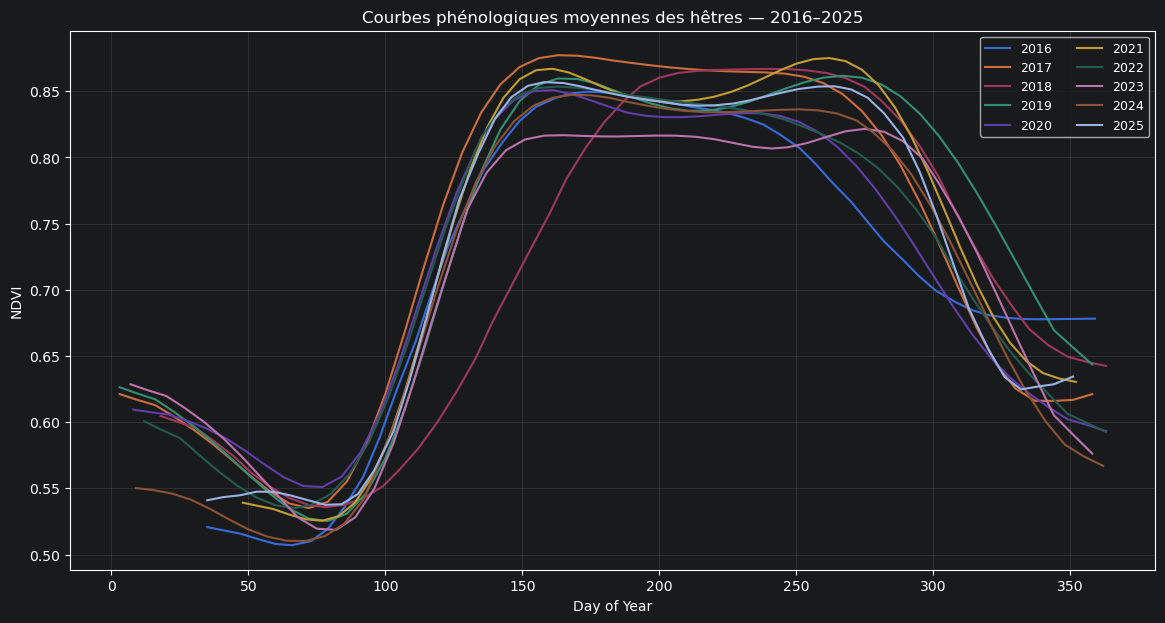

In [20]:
plt.figure(figsize=(14, 7))

for year, curve in phenology_curves_mean.items():

    plt.plot(
        curve.doy,
        curve,
        label=str(year)
    )

plt.xlabel("Day of Year")
plt.ylabel("NDVI")
plt.title(
    "Courbes phénologiques moyennes des hêtres — 2016–2025"
)

plt.legend(
    ncol=2,
    fontsize=9
)

plt.grid(alpha=0.2)

plt.show()

# importer les données terrain

In [21]:
collecteurs = pd.read_csv(
    "../data/Data_collecteurs_massane/collecteurs_massane_JH_VH_2015_2023.csv",
    sep=",",
    parse_dates=["date"]
)

collecteurs = collecteurs.sort_values(
    ["date", "station"]
).reset_index(drop=True)

collecteurs.columns

Index(['date', 'station', 'fag_feuil_ent', 'fag_feuil_cas', 'fag_feuil_gal',
       'fag_bourg', 'fag_ecail', 'fag_gal', 'fag_enigm', 'fag_ecorc',
       'fag_branch', 'fag_fain_intac', 'fag_fain_perc', 'fag_bog', 'fag_fleur',
       'fag_frui_avor', 'fag_indet', 'fag_necro'],
      dtype='str')

# comparaison graphique entre pheno et relevés

In [22]:

def plot_comparison(
    year,
    variables={
        "fag_feuil_ent": "darkgreen",
       # "fag_ecail":"lightgreen",
        "fag_fain_intac":"orange",
        "fag_fleur": "gold",
        # "fag_frui_avor": "brown"
    },
    jitter=1.5
):

    legend_labels = {
        "fag_feuil_ent": "Leaves",
        "fag_fleur": "Flowers",
        "fag_fain_intac": "Beech nuts"
    }

    # ========================================================
    # 1. DONNÉES COLLECTEURS
    # ========================================================

    collecteurs_year = collecteurs[
        collecteurs["date"].dt.year == year
    ].copy()

    # Moyenne de toutes les stations pour chaque date
    field = (
        collecteurs_year
        .groupby("date")[list(variables.keys())]
        .mean()
        .reset_index()
    )

    # Jour de l'année
    field["doy"] = field["date"].dt.dayofyear


    # ========================================================
    # 2. PHÉNOLOGIE NDVI
    # ========================================================

    pheno = phenology_curves_mean[year]

    pheno_doy = pheno["doy"].values
    pheno_ndvi = pheno.values


    # ========================================================
    # 3. NORMALISATION DU NDVI
    # ========================================================

    ndvi_min = np.nanmin(pheno_ndvi)
    ndvi_max = np.nanmax(pheno_ndvi)

    pheno_ndvi_norm = (
        (pheno_ndvi - ndvi_min)
        / (ndvi_max - ndvi_min)
    )


    # ========================================================
    # 4. NORMALISATION DES COLLECTEURS
    # ========================================================

    field_norm = field.copy()

    for variable in variables:

        values = field[variable].values

        vmin = np.nanmin(values)
        vmax = np.nanmax(values)

        field_norm[variable] = (
            (values - vmin)
            / (vmax - vmin)
        )


    # ========================================================
    # 5. PLOT
    # ========================================================

    fig, ax = plt.subplots(figsize=(12, 6))

    # --------------------------------------------------------
    # NDVI
    # --------------------------------------------------------

    ax.plot(
        pheno_doy,
        pheno_ndvi_norm,
        color="lightblue",
        linewidth=2.5,
        label="NDVI"
    )


    # --------------------------------------------------------
    # Collecteurs
    # --------------------------------------------------------

    # Décalages horizontaux répartis autour du DOY réel
    offsets = np.linspace(
        -jitter,
        jitter,
        len(variables)
    )

    for (variable, color), offset in zip(
        variables.items(),
        offsets
    ):

        ax.scatter(
            field_norm["doy"] + offset,
            field_norm[variable],
            color=color,
            s=55,
            label=legend_labels[variable]
        )


    # ========================================================
    # 6. MISE EN FORME
    # ========================================================

    legend_labels = {
        "fag_feuil_ent": "Leaves",
        "fag_fleur": "Flowers",
        "fag_fain_intac": "Beech nuts"
    }

    ax.set_xlabel("Day of year")
    ax.set_ylabel("Normalized value")

    ax.set_title(
        f"Beech phenology and collector observations — {year}"
    )

    ax.set_ylim(0, 1.05)

    ax.grid(
        alpha=0.3,
        linestyle="--"
    )

    ax.legend()

    plt.tight_layout()
    plt.show()



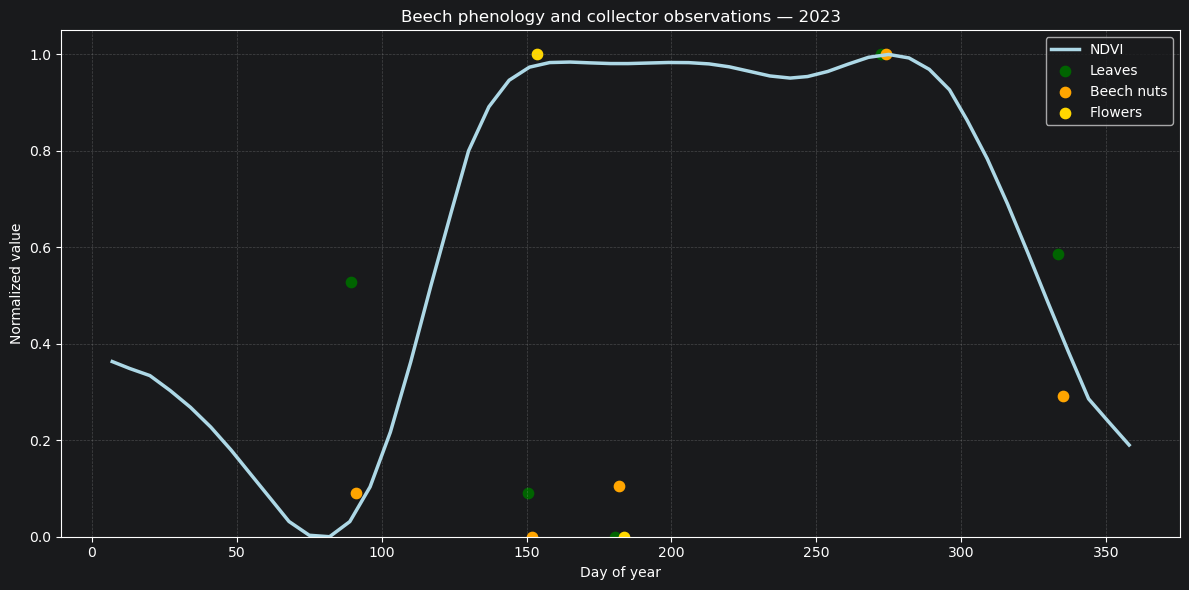

In [32]:
plot_comparison(2023)